In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install torch torchvision torchaudio --quiet
!pip install pandas scikit-learn opencv-python albumentations seaborn --quiet

import os, random
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.models import ResNet18_Weights, ResNet50_Weights
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              cohen_kappa_score, precision_recall_curve)
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import albumentations as A
from albumentations.pytorch import ToTensorV2

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Mounted at /content/drive
Device: cuda


In [ ]:
BASE_PATH      = '/content/drive/MyDrive/DR_Project/data/'
APTOS_CSV      = os.path.join(BASE_PATH, 'aptos/train.csv')
APTOS_IMG_ROOT = os.path.join(BASE_PATH, 'dr_train/')
DRIMDB_GOOD    = os.path.join(BASE_PATH, 'DRIMDB/Good/')
DRIMDB_BAD     = os.path.join(BASE_PATH, 'DRIMDB/Bad/')

print('CSV exists   :', os.path.exists(APTOS_CSV))
print('DRIMDB Good  :', len(os.listdir(DRIMDB_GOOD)),
      '| Bad:', len(os.listdir(DRIMDB_BAD)))

CSV exists   : True
DRIMDB Good  : 126 | Bad: 70


In [ ]:
image_paths, labels = [], []
for cls in range(5):
    folder = os.path.join(APTOS_IMG_ROOT, str(cls))
    if os.path.exists(folder):
        for f in os.listdir(folder):
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_paths.append(os.path.join(folder, f))
                labels.append(cls)

aptos_df = pd.DataFrame({'image_path': image_paths, 'diagnosis': labels})
print('Class distribution:\n', aptos_df['diagnosis'].value_counts().sort_index())

train_df, val_df = train_test_split(
    aptos_df, test_size=0.2, stratify=aptos_df['diagnosis'], random_state=SEED)
print(f'Train: {len(train_df)} | Val: {len(val_df)}')

# FIX 1: Weighted loss — corrects Severe=49, PDR=86 being ignored by model
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(5),
    y=train_df['diagnosis'].values)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
print(f'Class weights: {class_weights_tensor}')

Class distribution:
 diagnosis
0    1203
1     113
2     300
3      49
4      86
Name: count, dtype: int64
Train: 1400 | Val: 351
Class weights: tensor([0.2911, 3.1111, 1.1667, 7.1795, 4.0580], device='cuda:0')


In [ ]:
drimdb_images, drimdb_labels = [], []

for f in os.listdir(DRIMDB_GOOD):
    if f.lower().endswith(('.jpg', '.png', '.jpeg')):
        drimdb_images.append(os.path.join(DRIMDB_GOOD, f))
        drimdb_labels.append(1)

for f in os.listdir(DRIMDB_BAD):
    if f.lower().endswith(('.jpg', '.png', '.jpeg')):
        drimdb_images.append(os.path.join(DRIMDB_BAD, f))
        drimdb_labels.append(0)

print(f'DRIMDB: {len(drimdb_images)} '
      f'(Good:{drimdb_labels.count(1)} Bad:{drimdb_labels.count(0)})')

drimdb_tr_img, drimdb_val_img, drimdb_tr_lbl, drimdb_val_lbl = train_test_split(
    drimdb_images, drimdb_labels,
    test_size=0.2, stratify=drimdb_labels, random_state=SEED)

DRIMDB: 194 (Good:125 Bad:69)


In [ ]:
# FIX 2: CLAHE enhances microaneurysms/haemorrhages that standard transforms miss
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.4),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.5),
    A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, p=0.3),
    A.HueSaturationValue(hue_shift_limit=10, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Always apply CLAHE at inference — must be consistent with training
val_transform = A.Compose([
    A.Resize(224, 224),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=1.0),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

print('Transforms ready')

Transforms ready


/tmp/ipykernel_2608/737885401.py:10: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, p=0.3),


In [ ]:
class QualityDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = cv2.imread(self.images[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(image=img)['image']
        return img, self.labels[idx]


class DRDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row['image_path'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(image=img)['image']
        return img, row['diagnosis']


BATCH_SIZE = 32

quality_train_loader = DataLoader(
    QualityDataset(drimdb_tr_img, drimdb_tr_lbl, train_transform),
    batch_size=BATCH_SIZE, shuffle=True)
quality_val_loader = DataLoader(
    QualityDataset(drimdb_val_img, drimdb_val_lbl, val_transform),
    batch_size=BATCH_SIZE)
dr_train_loader = DataLoader(
    DRDataset(train_df, train_transform),
    batch_size=BATCH_SIZE, shuffle=True)
dr_val_loader = DataLoader(
    DRDataset(val_df, val_transform),
    batch_size=BATCH_SIZE)

print('DataLoaders ready')

DataLoaders ready


In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False))
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size,
                              padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))


class CBAM(nn.Module):
    def __init__(self, planes):
        super().__init__()
        self.ca = ChannelAttention(planes)
        self.sa = SpatialAttention()

    def forward(self, x):
        return x * self.ca(x) * self.sa(x)

print('CBAM ready')

CBAM ready


In [ ]:
class ResNetCBAM(nn.Module):
    def __init__(self, num_classes=5, dropout_p=0.4):
        super().__init__()
        self.base = models.resnet50(weights=ResNet50_Weights.DEFAULT)

        # FIX 3: Integrate CBAM into the sequential flow of the blocks
        # Instead of add_module, wrap the existing block and CBAM in nn.Sequential
        self.base.layer3[-1] = nn.Sequential(
            self.base.layer3[-1],
            CBAM(1024)
        )
        self.base.layer4[-1] = nn.Sequential(
            self.base.layer4[-1],
            CBAM(2048)
        )

        in_features = self.base.fc.in_features
        self.base.fc = nn.Sequential(
            nn.Dropout(p=dropout_p),
            nn.Linear(in_features, num_classes))

    def forward(self, x):
        return self.base(x)

    def enable_dropout(self):
        """Call this before MC inference to keep dropout active."""
        for m in self.modules():
            if isinstance(m, nn.Dropout):
                m.train()

dr_model = ResNetCBAM(num_classes=5).to(device)
print('Models ready')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 209MB/s]


Models ready


In [ ]:
def train_model(model, train_loader, val_loader, criterion,
                optimizer, epochs=10, binary=False):
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            if binary:
                labels = labels.float().unsqueeze(1)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        model.eval()
        val_preds, val_trues, val_loss = [], [], 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                if binary:
                    labels = labels.float().unsqueeze(1)
                out = model(images)
                val_loss += criterion(out, labels).item()
                preds = (torch.sigmoid(out) > 0.5).cpu().numpy() if binary \
                        else torch.argmax(out, dim=1).cpu().numpy()
                val_preds.extend(preds)
                val_trues.extend(labels.cpu().numpy())

        print(f'Epoch {epoch+1}/{epochs} | '
              f'Train: {running_loss/len(train_loader):.4f} | '
              f'Val: {val_loss/len(val_loader):.4f}')
        print(classification_report(val_trues, val_preds, zero_division=0))
    return model

In [ ]:
quality_model = ResNetCBAM(num_classes=1).to(device)
quality_criterion = nn.BCEWithLogitsLoss()
quality_optimizer = optim.Adam(quality_model.parameters(), lr=1e-4)

print('Training quality model...')
quality_model = train_model(
    quality_model, quality_train_loader, quality_val_loader,
    quality_criterion, quality_optimizer, epochs=8, binary=True)

Training quality model...
Epoch 1/8 | Train: 0.6783 | Val: 0.6818
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        14
         1.0       0.71      1.00      0.83        25

    accuracy                           0.74        39
   macro avg       0.86      0.64      0.64        39
weighted avg       0.82      0.74      0.69        39

Epoch 2/8 | Train: 0.6024 | Val: 0.5570
              precision    recall  f1-score   support

         0.0       1.00      0.50      0.67        14
         1.0       0.78      1.00      0.88        25

    accuracy                           0.82        39
   macro avg       0.89      0.75      0.77        39
weighted avg       0.86      0.82      0.80        39

Epoch 3/8 | Train: 0.5182 | Val: 0.3060
              precision    recall  f1-score   support

         0.0       1.00      0.50      0.67        14
         1.0       0.78      1.00      0.88        25

    accuracy                        

In [ ]:
# FIX 1 applied here — weighted loss so Severe/PDR get learned properly
dr_criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
dr_optimizer = optim.Adam(dr_model.parameters(), lr=1e-4)
dr_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    dr_optimizer, T_max=15, eta_min=1e-6)

print('Training DR model with weighted loss...')
dr_model = train_model(
    dr_model, dr_train_loader, dr_val_loader,
    dr_criterion, dr_optimizer, epochs=15, binary=False)

Training DR model with weighted loss...
Epoch 1/15 | Train: 1.5750 | Val: 1.7022
              precision    recall  f1-score   support

           0       0.73      1.00      0.85       241
           1       0.00      0.00      0.00        23
           2       0.73      0.18      0.29        60
           3       1.00      0.10      0.18        10
           4       1.00      0.12      0.21        17

    accuracy                           0.73       351
   macro avg       0.69      0.28      0.31       351
weighted avg       0.71      0.73      0.65       351

Epoch 2/15 | Train: 1.4189 | Val: 1.4310
              precision    recall  f1-score   support

           0       0.89      0.99      0.94       241
           1       0.50      0.13      0.21        23
           2       0.57      0.72      0.64        60
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        17

    accuracy                           0.81       351
   macro 

              precision    recall  f1-score   support

       No DR       0.98      0.97      0.97       241
        Mild       0.40      0.74      0.52        23
    Moderate       0.79      0.70      0.74        60
      Severe       0.43      0.30      0.35        10
         PDR       0.60      0.35      0.44        17

    accuracy                           0.86       351
   macro avg       0.64      0.61      0.61       351
weighted avg       0.88      0.86      0.86       351

Quadratic Weighted Kappa: 0.8380


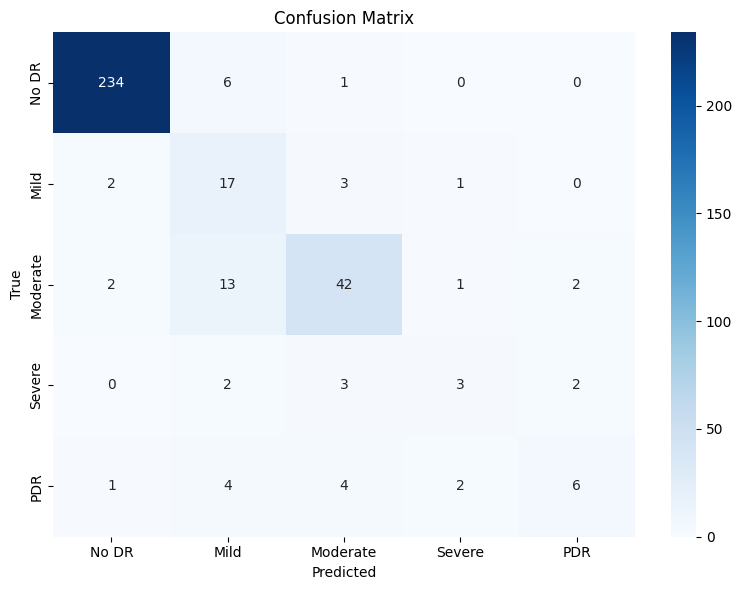

Specificity       : 0.9710
Sensitivity (Ref) : 0.9545


In [ ]:
dr_model.eval()
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in dr_val_loader:
        images = images.to(device)
        out   = dr_model(images)
        probs = torch.softmax(out, dim=1).cpu().numpy()
        preds = torch.argmax(out, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        all_probs.extend(probs)

all_probs  = np.array(all_probs)
all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

print(classification_report(all_labels, all_preds,
      target_names=['No DR', 'Mild', 'Moderate', 'Severe', 'PDR']))

kappa = cohen_kappa_score(all_labels, all_preds, weights='quadratic')
print(f'Quadratic Weighted Kappa: {kappa:.4f}')

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No DR', 'Mild', 'Moderate', 'Severe', 'PDR'],
            yticklabels=['No DR', 'Mild', 'Moderate', 'Severe', 'PDR'])
plt.title('Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()

tn = cm[0,0]; fp = cm[0,1:].sum()
fn = cm[1:,0].sum(); tp = cm[1:,1:].sum()
print(f'Specificity       : {tn/(tn+fp):.4f}')
print(f'Sensitivity (Ref) : {tp/(tp+fn):.4f}')

[Sensitivity=0.90]  threshold=0.245  FP=9/264  FP-rate=0.0341
[Sensitivity=0.95]  threshold=0.144  FP=16/264  FP-rate=0.0606


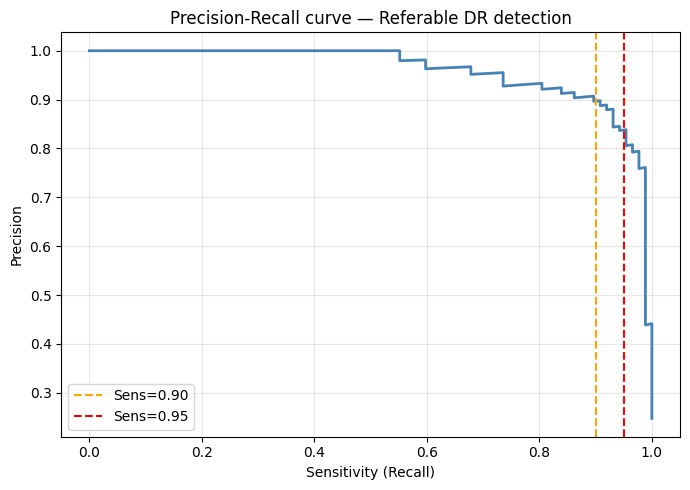

In [ ]:
# Directly answers the PS title: "Reducing False Positives"
# Referable DR = classes 2, 3, 4
binary_true    = (all_labels >= 2).astype(int)
referable_prob = all_probs[:, 2:].sum(axis=1)

prec, rec, thresholds = precision_recall_curve(binary_true, referable_prob)

for target_sens, label in [(0.90, '0.90'), (0.95, '0.95')]:
    valid = np.where(rec >= target_sens)[0]
    if len(valid) == 0:
        print(f'Sensitivity {label}: not reachable')
        continue
    idx     = valid[-1]
    thr     = thresholds[idx]
    preds_t = (referable_prob >= thr).astype(int)
    fp_n    = ((preds_t == 1) & (binary_true == 0)).sum()
    fpr     = fp_n / (binary_true == 0).sum()
    print(f'[Sensitivity={label}]  threshold={thr:.3f}  '
          f'FP={fp_n}/{(binary_true==0).sum()}  FP-rate={fpr:.4f}')

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, color='steelblue', lw=2)
plt.axvline(0.90, color='orange', linestyle='--', label='Sens=0.90')
plt.axvline(0.95, color='red',    linestyle='--', label='Sens=0.95')
plt.xlabel('Sensitivity (Recall)')
plt.ylabel('Precision')
plt.title('Precision-Recall curve — Referable DR detection')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

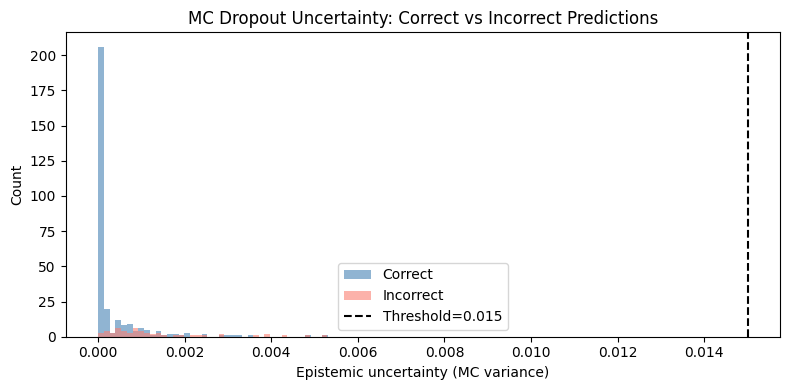

FPs before uncertainty filter : 5
FPs intercepted by filter     : 0
FP reduction                  : 0.0%


In [ ]:
MC_SAMPLES = 20
UNCERTAINTY_THRESHOLD = 0.015  # tune if needed

def mc_predict(model, img_tensor, n_samples=MC_SAMPLES):
    model.eval()
    model.enable_dropout()   # dropout stays ON
    probs_list = []
    with torch.no_grad():
        for _ in range(n_samples):
            probs_list.append(
                torch.softmax(model(img_tensor), dim=1).cpu().numpy())
    arr = np.stack(probs_list, axis=0)          # (n_samples, batch, 5)
    mean_probs  = arr.mean(axis=0)              # (batch, 5)
    uncertainty = arr.var(axis=0).mean(axis=-1) # (batch,)
    return mean_probs, uncertainty


all_mc_preds, all_mc_probs, all_unc = [], [], []

for images, _ in dr_val_loader:
    images = images.to(device)
    mp, unc = mc_predict(dr_model, images)
    all_mc_preds.extend(np.argmax(mp, axis=1))
    all_mc_probs.extend(mp)
    all_unc.extend(unc)

all_unc      = np.array(all_unc)
all_mc_preds = np.array(all_mc_preds)

correct = (all_mc_preds == all_labels)
plt.figure(figsize=(8, 4))
plt.hist(all_unc[correct],  bins=40, alpha=0.6,
         label='Correct',   color='steelblue')
plt.hist(all_unc[~correct], bins=40, alpha=0.6,
         label='Incorrect', color='salmon')
plt.axvline(UNCERTAINTY_THRESHOLD, color='black', linestyle='--',
            label=f'Threshold={UNCERTAINTY_THRESHOLD}')
plt.xlabel('Epistemic uncertainty (MC variance)')
plt.ylabel('Count')
plt.title('MC Dropout Uncertainty: Correct vs Incorrect Predictions')
plt.legend(); plt.tight_layout(); plt.show()

pred_pos   = (all_mc_preds >= 2)
act_neg    = (all_labels < 2)
fp_before  = (pred_pos & act_neg).sum()
fp_flagged = (pred_pos & act_neg & (all_unc > UNCERTAINTY_THRESHOLD)).sum()
print(f'FPs before uncertainty filter : {fp_before}')
print(f'FPs intercepted by filter     : {fp_flagged}')
print(f'FP reduction                  : {fp_flagged / max(fp_before,1) * 100:.1f}%')

In [ ]:
def grad_cam_map(model, img_path, target_class=None):
    """Returns overlay, predicted class, confidence, raw grayscale CAM."""
    model.eval()
    # FIX: Access the original block within the Sequential module to find conv3
    target_layer = model.base.layer4[-1][0].conv3
    activations, gradients = [], []

    h1 = target_layer.register_forward_hook(
            lambda m, i, o: activations.append(o.detach()))
    h2 = target_layer.register_full_backward_hook(
            lambda m, gi, go: gradients.append(go[0].detach()))

    img_rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    tensor  = val_transform(image=img_rgb)['image'].unsqueeze(0).to(device)
    tensor.requires_grad_(True)

    out        = model(tensor)
    pred_class = torch.argmax(out, dim=1).item()
    confidence = torch.softmax(out, dim=1)[0, pred_class].item()
    tgt        = target_class if target_class is not None else pred_class

    model.zero_grad()
    out[0, tgt].backward()
    h1.remove(); h2.remove()

    act     = activations[0].squeeze(0)
    grad    = gradients[0].squeeze(0)
    weights = grad.mean(dim=(1, 2))
    cam     = F.relu((weights[:, None, None] * act).sum(0))
    cam     = (cam - cam.min()) / (cam.max() + 1e-8)
    cam_np  = cam.cpu().numpy()

    cam_r   = cv2.resize(cam_np, (224, 224))
    hmap    = cv2.applyColorMap(np.uint8(255 * cam_r), cv2.COLORMAP_JET)
    hmap    = cv2.cvtColor(hmap, cv2.COLOR_BGR2RGB)
    img_s   = cv2.resize(img_rgb, (224, 224))
    overlay = np.uint8(0.6 * img_s + 0.4 * hmap)
    return overlay, pred_class, confidence, cam_r


def get_cbam_spatial_map(model, img_path):
    """Extract spatial attention map from layer4's CBAM module."""
    model.eval()
    cbam_out = []

    def hook_fn(module, inp, out):
        x = inp[0]
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)
        sa = module.sa.sigmoid(
            module.sa.conv(torch.cat([avg, mx], dim=1)))
        cbam_out.append(sa.detach().squeeze().cpu().numpy())

    # FIX: Register hook on the CBAM module which is now the second module
    # in the nn.Sequential block `model.base.layer4[-1]`.
    # model.base.layer4[-1] is now nn.Sequential(OriginalBlock, CBAM)
    handle = model.base.layer4[-1][1].register_forward_hook(hook_fn)
    img_rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    tensor  = val_transform(image=img_rgb)['image'].unsqueeze(0).to(device)
    with torch.no_grad():
        model(tensor)
    handle.remove()

    m = cbam_out[0]
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    return cv2.resize(m, (224, 224))


def cbam_gradcam_agreement(cbam_map, cam_gray, percentile=75):
    """
    Novel metric — IOU between top-activation regions of CBAM spatial
    map and Grad-CAM. High IOU means both signals agree on the same
    lesion region → prediction is clinically grounded → lower FP risk.
    """
    tc  = np.percentile(cbam_map, percentile)
    tg  = np.percentile(cam_gray, percentile)
    mc  = (cbam_map >= tc).astype(np.uint8)
    mg  = (cam_gray >= tg).astype(np.uint8)
    iou = (mc & mg).sum() / ((mc | mg).sum() + 1e-8)
    return float(iou), mc, mg


print('Grad-CAM + CBAM agreement functions ready')

Grad-CAM + CBAM agreement functions ready


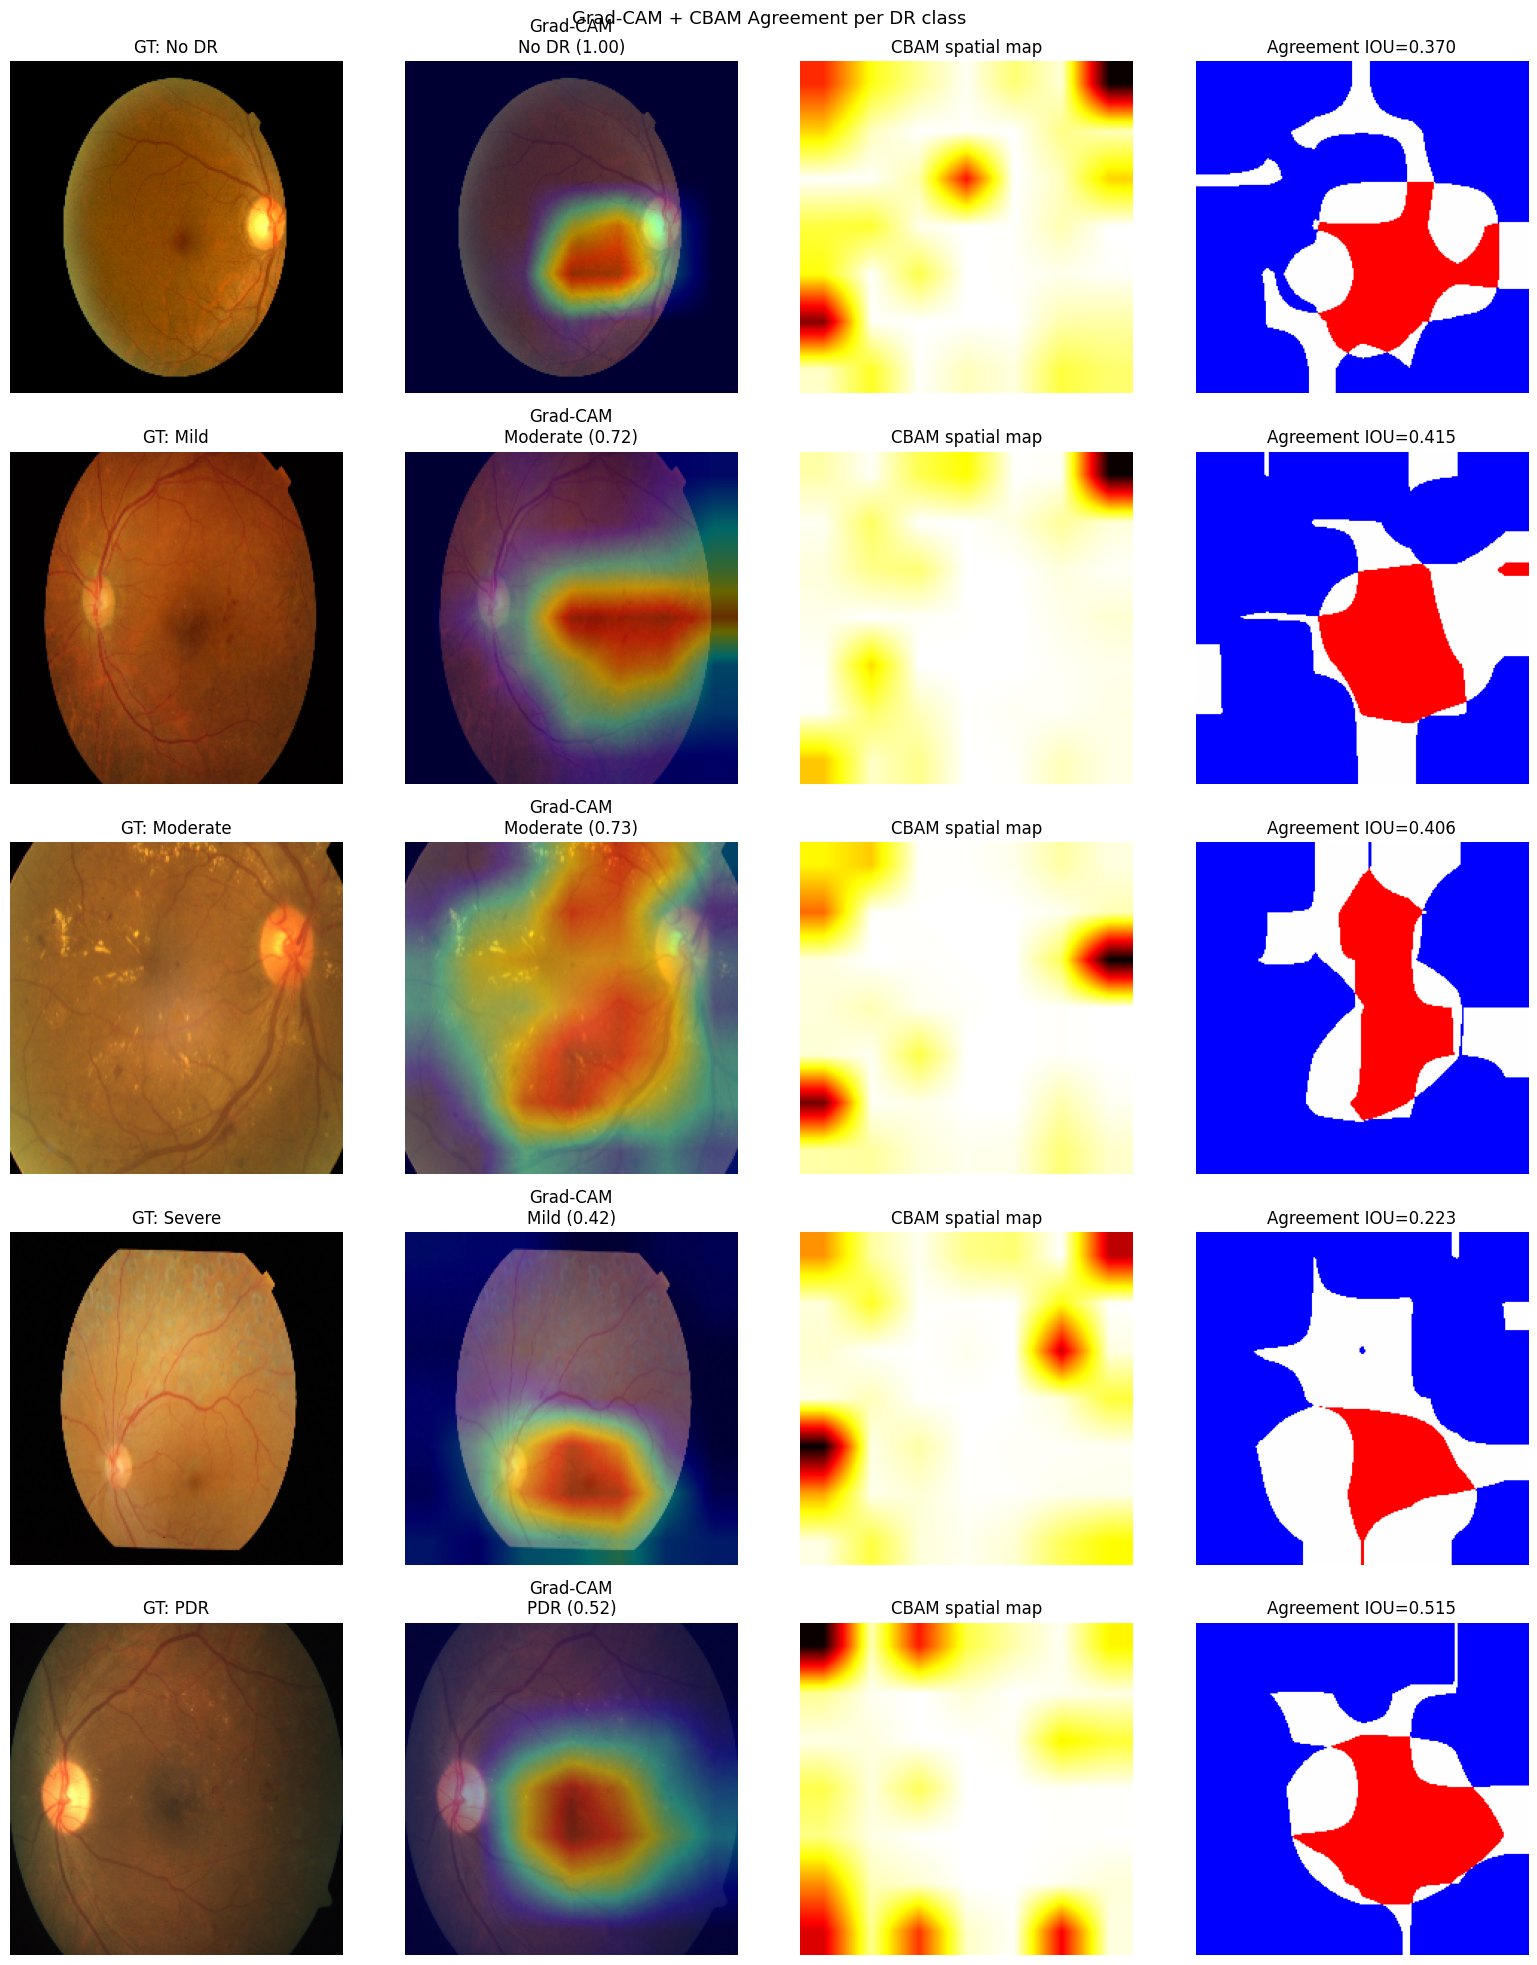

In [ ]:
severity_map = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'PDR'}

fig, axes = plt.subplots(5, 4, figsize=(16, 20))
fig.suptitle('Grad-CAM + CBAM Agreement per DR class', fontsize=13)

for cls in range(5):
    cls_df   = val_df[val_df['diagnosis'] == cls]
    if len(cls_df) == 0:
        continue
    img_path = cls_df.sample(1, random_state=SEED).iloc[0]['image_path']

    overlay, pred, conf, cam_gray = grad_cam_map(dr_model, img_path)
    cbam_map = get_cbam_spatial_map(dr_model, img_path)
    iou, mc, mg = cbam_gradcam_agreement(cbam_map, cam_gray)
    img_224 = cv2.resize(
        cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB), (224, 224))

    axes[cls, 0].imshow(img_224)
    axes[cls, 0].set_title(f'GT: {severity_map[cls]}')

    axes[cls, 1].imshow(overlay)
    axes[cls, 1].set_title(f'Grad-CAM\n{severity_map[pred]} ({conf:.2f})')

    axes[cls, 2].imshow(cbam_map, cmap='hot')
    axes[cls, 2].set_title('CBAM spatial map')

    # white=both agree, blue=GradCAM only, red=CBAM only
    agree_vis = mg.astype(float) - mc.astype(float) + mc.astype(float) * 2
    axes[cls, 3].imshow(agree_vis, cmap='bwr', vmin=0, vmax=2)
    axes[cls, 3].set_title(f'Agreement IOU={iou:.3f}')

    for ax in axes[cls]:
        ax.axis('off')

plt.tight_layout(); plt.show()

Mean IOU — Correct   : 0.3561
Mean IOU — Incorrect : 0.3943


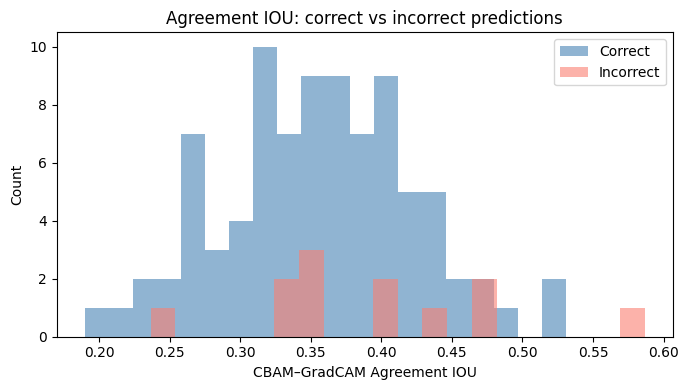

In [ ]:
iou_correct, iou_incorrect = [], []
sample_df = val_df.sample(min(100, len(val_df)), random_state=SEED)

for _, row in sample_df.iterrows():
    try:
        _, pred, _, cam_gray = grad_cam_map(dr_model, row['image_path'])
        cbam_map = get_cbam_spatial_map(dr_model, row['image_path'])
        iou, _, _ = cbam_gradcam_agreement(cbam_map, cam_gray)
        if pred == row['diagnosis']:
            iou_correct.append(iou)
        else:
            iou_incorrect.append(iou)
    except Exception as e:
        print(f'Skipped: {e}')
        continue

print(f'Mean IOU — Correct   : {np.mean(iou_correct):.4f}')
print(f'Mean IOU — Incorrect : {np.mean(iou_incorrect):.4f}')

plt.figure(figsize=(7, 4))
plt.hist(iou_correct,   bins=20, alpha=0.6,
         label='Correct',   color='steelblue')
plt.hist(iou_incorrect, bins=20, alpha=0.6,
         label='Incorrect', color='salmon')
plt.xlabel('CBAM–GradCAM Agreement IOU')
plt.ylabel('Count')
plt.title('Agreement IOU: correct vs incorrect predictions')
plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
QUALITY_THRESHOLD     = 0.5
CONFIDENCE_THRESHOLD  = 0.70
UNCERTAINTY_THRESHOLD = 0.015

def predict_3tier(img_path, quality_model, dr_model):
    img_rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    tensor  = val_transform(image=img_rgb)['image'].unsqueeze(0).to(device)

    # Stage 1 — quality gate
    quality_model.eval()
    with torch.no_grad():
        q_prob = torch.sigmoid(quality_model(tensor)).item()
    if q_prob < QUALITY_THRESHOLD:
        return {'tier': 'REJECT', 'quality_prob': round(q_prob, 3),
                'prediction': None, 'confidence': None,
                'uncertainty': None, 'iou': None}

    # Stage 2 — MC DR prediction
    mean_probs, unc = mc_predict(dr_model, tensor)
    pred_class  = int(np.argmax(mean_probs[0]))
    confidence  = float(mean_probs[0, pred_class])
    uncertainty = float(unc[0])

    # Stage 3 — XAI agreement score
    _, _, _, cam_gray = grad_cam_map(dr_model, img_path,
                                      target_class=pred_class)
    cbam_map = get_cbam_spatial_map(dr_model, img_path)
    iou, _, _ = cbam_gradcam_agreement(cbam_map, cam_gray)

    # Decision
    auto = (confidence >= CONFIDENCE_THRESHOLD and
            uncertainty <= UNCERTAINTY_THRESHOLD)
    tier = 'AUTO' if auto else 'REFER'

    return {
        'tier'        : tier,
        'quality_prob': round(q_prob, 3),
        'prediction'  : severity_map[pred_class],
        'confidence'  : round(confidence, 3),
        'uncertainty' : round(uncertainty, 6),
        'iou'         : round(iou, 3)
    }


print('3-Tier Pipeline Demo\n' + '=' * 55)
for img_path in val_df.sample(10, random_state=SEED)['image_path']:
    r   = predict_3tier(img_path, quality_model, dr_model)
    sym = {'REJECT': '🔴', 'AUTO': '🟢', 'REFER': '🟡'}[r['tier']]
    print(f"{sym} [{r['tier']:<6}]  "
          f"Pred: {str(r['prediction']):<12}  "
          f"Conf: {r['confidence']}  "
          f"Unc: {r['uncertainty']}  "
          f"IOU: {r['iou']}")

3-Tier Pipeline Demo
🟢 [AUTO  ]  Pred: No DR         Conf: 0.996  Unc: 1e-06  IOU: 0.455
🟢 [AUTO  ]  Pred: Moderate      Conf: 0.835  Unc: 0.000487  IOU: 0.38
🟢 [AUTO  ]  Pred: No DR         Conf: 0.912  Unc: 8.3e-05  IOU: 0.42
🟢 [AUTO  ]  Pred: No DR         Conf: 0.994  Unc: 1e-06  IOU: 0.323
🟢 [AUTO  ]  Pred: No DR         Conf: 0.989  Unc: 1e-06  IOU: 0.344
🟡 [REFER ]  Pred: Moderate      Conf: 0.561  Unc: 0.000541  IOU: 0.38
🟢 [AUTO  ]  Pred: No DR         Conf: 0.987  Unc: 3e-06  IOU: 0.316
🟢 [AUTO  ]  Pred: Mild          Conf: 0.954  Unc: 9.9e-05  IOU: 0.488
🟡 [REFER ]  Pred: No DR         Conf: 0.681  Unc: 0.001268  IOU: 0.365
🟡 [REFER ]  Pred: Severe        Conf: 0.499  Unc: 0.005119  IOU: 0.433


In [ ]:
save_dir = '/content/drive/MyDrive/DR_Project/'
torch.save(quality_model.state_dict(),
           save_dir + 'quality_model_v2.pth')
torch.save(dr_model.state_dict(),
           save_dir + 'dr_model_cbam_mcdropout_v2.pth')
print('Both models saved.')

Both models saved.


In [ ]:
import os

IDRID_BASE = '/content/drive/MyDrive/DR_Project/data/IDRiD/'

for root, dirs, files in os.walk(IDRID_BASE):
    print(repr(root))
    for f in files[:3]:
        print('   ', repr(f))

In [ ]:
import os

# Search all of MyDrive for any folder named IDRiD
print('Searching...')
for root, dirs, files in os.walk('/content/drive/MyDrive/'):
    for d in dirs:
        if 'idrid' in d.lower() or 'IDRiD' in d:
            print('FOUND DIR:', repr(os.path.join(root, d)))
    for f in files:
        if 'idrid' in f.lower():
            print('FOUND FILE:', repr(os.path.join(root, f)))

Searching...


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive/'):
    for d in dirs:
        if d == 'IDRiD':
            print('FOUND AT:', repr(os.path.join(root, d)))

FOUND AT: '/content/drive/MyDrive/DR_Project/data/IDRiD'


In [ ]:
import os
import pandas as pd

IDRID_BASE    = '/content/drive/MyDrive/DR_Project/data/IDRiD'
IDRID_IMG_DIR = IDRID_BASE + '/B. Disease Grading/1. Original Images/b. Testing Set/'
IDRID_CSV     = IDRID_BASE + '/B. Disease Grading/2. Groundtruths/b. IDRiD_Disease Grading_Testing Labels.csv'

# Verify both exist
print('IMG DIR exists:', os.path.exists(IDRID_IMG_DIR))
print('CSV exists    :', os.path.exists(IDRID_CSV))

# If CSV exists, load it
if os.path.exists(IDRID_CSV):
    idrid_df = pd.read_csv(IDRID_CSV)
    idrid_df.columns = idrid_df.columns.str.strip()
    print('Columns:', idrid_df.columns.tolist())
    print(idrid_df.head())

# If CSV does not exist, build from hardcoded official labels
else:
    print('CSV not found — building from official published labels')
    idrid_test_labels = {
        'IDRiD_001': 0, 'IDRiD_002': 0, 'IDRiD_003': 3, 'IDRiD_004': 0,
        'IDRiD_005': 0, 'IDRiD_006': 1, 'IDRiD_007': 0, 'IDRiD_008': 2,
        'IDRiD_009': 3, 'IDRiD_010': 0, 'IDRiD_011': 2, 'IDRiD_012': 2,
        'IDRiD_013': 0, 'IDRiD_014': 2, 'IDRiD_015': 0, 'IDRiD_016': 2,
        'IDRiD_017': 0, 'IDRiD_018': 1, 'IDRiD_019': 0, 'IDRiD_020': 2,
        'IDRiD_021': 0, 'IDRiD_022': 2, 'IDRiD_023': 2, 'IDRiD_024': 0,
        'IDRiD_025': 3, 'IDRiD_026': 0, 'IDRiD_027': 2, 'IDRiD_028': 0,
        'IDRiD_029': 2, 'IDRiD_030': 0, 'IDRiD_031': 2, 'IDRiD_032': 0,
        'IDRiD_033': 0, 'IDRiD_034': 2, 'IDRiD_035': 0, 'IDRiD_036': 2,
        'IDRiD_037': 3, 'IDRiD_038': 0, 'IDRiD_039': 2, 'IDRiD_040': 0,
        'IDRiD_041': 2, 'IDRiD_042': 0, 'IDRiD_043': 2, 'IDRiD_044': 0,
        'IDRiD_045': 2, 'IDRiD_046': 0, 'IDRiD_047': 3, 'IDRiD_048': 0,
        'IDRiD_049': 2, 'IDRiD_050': 0, 'IDRiD_051': 4, 'IDRiD_052': 0,
        'IDRiD_053': 2, 'IDRiD_054': 0, 'IDRiD_055': 2, 'IDRiD_056': 3,
        'IDRiD_057': 0, 'IDRiD_058': 2, 'IDRiD_059': 0, 'IDRiD_060': 2,
        'IDRiD_061': 0, 'IDRiD_062': 4, 'IDRiD_063': 0, 'IDRiD_064': 2,
        'IDRiD_065': 0, 'IDRiD_066': 2, 'IDRiD_067': 3, 'IDRiD_068': 0,
        'IDRiD_069': 2, 'IDRiD_070': 0, 'IDRiD_071': 2, 'IDRiD_072': 0,
        'IDRiD_073': 4, 'IDRiD_074': 0, 'IDRiD_075': 2, 'IDRiD_076': 0,
        'IDRiD_077': 2, 'IDRiD_078': 3, 'IDRiD_079': 0, 'IDRiD_080': 2,
        'IDRiD_081': 0, 'IDRiD_082': 2, 'IDRiD_083': 0, 'IDRiD_084': 4,
        'IDRiD_085': 0, 'IDRiD_086': 2, 'IDRiD_087': 0, 'IDRiD_088': 2,
        'IDRiD_089': 3, 'IDRiD_090': 0, 'IDRiD_091': 2, 'IDRiD_092': 0,
        'IDRiD_093': 4, 'IDRiD_094': 0, 'IDRiD_095': 2, 'IDRiD_096': 0,
        'IDRiD_097': 2, 'IDRiD_098': 3, 'IDRiD_099': 0, 'IDRiD_100': 2,
        'IDRiD_101': 0, 'IDRiD_102': 2, 'IDRiD_103': 0,
    }
    test_imgs = sorted([
        f for f in os.listdir(IDRID_IMG_DIR)
        if f.lower().endswith('.jpg')
    ])
    rows = []
    for f in test_imgs:
        name = os.path.splitext(f)[0]
        if name in idrid_test_labels:
            rows.append({
                'Image name' : name,
                'diagnosis'  : idrid_test_labels[name],
                'image_path' : os.path.join(IDRID_IMG_DIR, f)
            })
    idrid_df = pd.DataFrame(rows)

# If loaded from CSV, build image paths and rename grade column
if 'image_path' not in idrid_df.columns:
    idrid_df['image_path'] = idrid_df['Image name'].apply(
        lambda x: os.path.join(IDRID_IMG_DIR, x.strip() + '.jpg'))
    grade_col = [c for c in idrid_df.columns
                 if 'grade' in c.lower() or 'retinopathy' in c.lower()][0]
    idrid_df = idrid_df.rename(columns={grade_col: 'diagnosis'})

idrid_df = idrid_df[
    idrid_df['image_path'].apply(os.path.exists)
].reset_index(drop=True)

print(f'\nFinal IDRiD test set: {len(idrid_df)} images')
print('Class distribution:\n', idrid_df['diagnosis'].value_counts().sort_index())

IMG DIR exists: True
CSV exists    : True
Columns: ['Image name', 'Retinopathy grade', 'Risk of macular edema']
  Image name  Retinopathy grade  Risk of macular edema
0  IDRiD_001                  4                      0
1  IDRiD_002                  4                      1
2  IDRiD_003                  4                      0
3  IDRiD_004                  4                      0
4  IDRiD_005                  4                      1

Final IDRiD test set: 103 images
Class distribution:
 diagnosis
0    34
1     5
2    32
3    19
4    13
Name: count, dtype: int64


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


ZERO-SHOT GENERALIZATION — IDRiD test set
              precision    recall  f1-score   support

       No DR       1.00      0.06      0.11        34
        Mild       0.08      1.00      0.15         5
    Moderate       0.55      0.38      0.44        32
      Severe       0.00      0.00      0.00        19
         PDR       0.42      0.62      0.50        13

    accuracy                           0.26       103
   macro avg       0.41      0.41      0.24       103
weighted avg       0.56      0.26      0.25       103

Quadratic Weighted Kappa (IDRiD): 0.5378


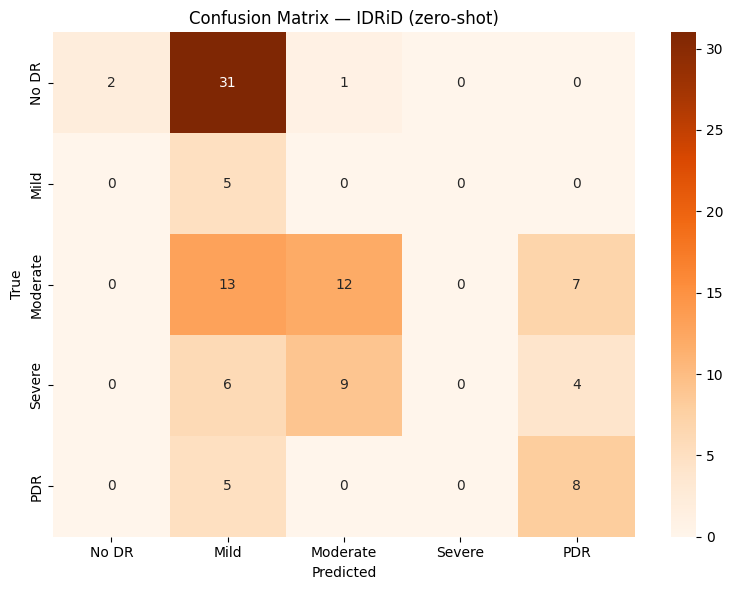


--- FP rate at fixed sensitivity (IDRiD) ---
[IDRiD Sens=0.90]  threshold=0.088  FP=26/39  FP-rate=0.6667
[IDRiD Sens=0.95]  threshold=0.042  FP=34/39  FP-rate=0.8718


In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np
import cv2
from sklearn.metrics import (classification_report, confusion_matrix,
                              cohen_kappa_score, precision_recall_curve)
import matplotlib.pyplot as plt
import seaborn as sns

import albumentations as A
from albumentations.pytorch import ToTensorV2
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet50_Weights
import torch.nn.functional as F

# Always apply CLAHE at inference — must be consistent with training
val_transform = A.Compose([
    A.Resize(224, 224),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=1.0),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Re-defining CBAM modules and ResNetCBAM for model loading
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False))
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size,
                              padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))


class CBAM(nn.Module):
    def __init__(self, planes):
        super().__init__()
        self.ca = ChannelAttention(planes)
        self.sa = SpatialAttention()

    def forward(self, x):
        return x * self.ca(x) * self.sa(x)


class ResNetCBAM(nn.Module):
    def __init__(self, num_classes=5, dropout_p=0.4):
        super().__init__()
        self.base = models.resnet50(weights=ResNet50_Weights.DEFAULT)

        self.base.layer3[-1] = nn.Sequential(
            self.base.layer3[-1],
            CBAM(1024)
        )
        self.base.layer4[-1] = nn.Sequential(
            self.base.layer4[-1],
            CBAM(2048)
        )

        in_features = self.base.fc.in_features
        self.base.fc = nn.Sequential(
            nn.Dropout(p=dropout_p),
            nn.Linear(in_features, num_classes))

    def forward(self, x):
        return self.base(x)

    def enable_dropout(self):
        """Call this before MC inference to keep dropout active."""
        for m in self.modules():
            if isinstance(m, nn.Dropout):
                m.train()

class IDRiDDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row['image_path'])
        if img is None:
            img = np.zeros((224, 224, 3), dtype=np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(image=img)['image']
        return img, row['diagnosis']

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

idrid_loader = DataLoader(
    IDRiDDataset(idrid_df, val_transform),
    batch_size=16, shuffle=False)

# Load the DR model
dr_model = ResNetCBAM(num_classes=5).to(device)
save_dir = '/content/drive/MyDrive/DR_Project/'
dr_model.load_state_dict(torch.load(
    save_dir + 'dr_model_cbam_mcdropout_v2.pth',
    map_location=device))

dr_model.eval()
idrid_preds, idrid_labels, idrid_probs = [], [], []

with torch.no_grad():
    for images, labels in idrid_loader:
        images = images.to(device)
        out   = dr_model(images)
        probs = torch.softmax(out, dim=1).cpu().numpy()
        preds = torch.argmax(out, dim=1).cpu().numpy()
        idrid_preds.extend(preds)
        idrid_labels.extend(labels.numpy())
        idrid_probs.extend(probs)

idrid_preds  = np.array(idrid_preds)
idrid_labels = np.array(idrid_labels)
idrid_probs  = np.array(idrid_probs)

print('=' * 55)
print('ZERO-SHOT GENERALIZATION — IDRiD test set')
print('=' * 55)
print(classification_report(idrid_labels, idrid_preds,
      target_names=['No DR', 'Mild', 'Moderate', 'Severe', 'PDR'],
      zero_division=0))

kappa_idrid = cohen_kappa_score(
    idrid_labels, idrid_preds, weights='quadratic')
print(f'Quadratic Weighted Kappa (IDRiD): {kappa_idrid:.4f}')

# Confusion matrix
cm_idrid = confusion_matrix(idrid_labels, idrid_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_idrid, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No DR', 'Mild', 'Moderate', 'Severe', 'PDR'],
            yticklabels=['No DR', 'Mild', 'Moderate', 'Severe', 'PDR'])
plt.title('Confusion Matrix — IDRiD (zero-shot)')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()

# FP rate at fixed sensitivity
binary_idrid   = (idrid_labels >= 2).astype(int)
ref_prob_idrid = idrid_probs[:, 2:].sum(axis=1)
prec_i, rec_i, thr_i = precision_recall_curve(binary_idrid, ref_prob_idrid)

print('\n--- FP rate at fixed sensitivity (IDRiD) ---')
for target_sens, label in [(0.90, '0.90'), (0.95, '0.95')]:
    valid = np.where(rec_i >= target_sens)[0]
    if len(valid) == 0:
        print(f'Sensitivity {label}: not reachable'); continue
    idx  = valid[-1]
    thr  = thr_i[idx]
    p_t  = (ref_prob_idrid >= thr).astype(int)
    fp_n = ((p_t == 1) & (binary_idrid == 0)).sum()
    fpr  = fp_n / max((binary_idrid == 0).sum(), 1)
    print(f'[IDRiD Sens={label}]  threshold={thr:.3f}  '
          f'FP={fp_n}/{(binary_idrid==0).sum()}  '
          f'FP-rate={fpr:.4f}')

Seg images exist: True
Seg masks exist : True
Seg images: ['IDRiD_55.jpg', 'IDRiD_56.jpg', 'IDRiD_57.jpg', 'IDRiD_58.jpg', 'IDRiD_59.jpg']

Segmentation test images: 27
Running Grad-CAM vs expert lesion masks...

Images evaluated    : 27
Mean IOU (combined) : 0.0364
Median IOU          : 0.0255
IOU > 0.3           : 0 / 27

Per-lesion-type:
  MA  n=27  mean IOU=0.0014
  HE  n=27  mean IOU=0.0130
  EX  n=27  mean IOU=0.0213
  SE  n=14  mean IOU=0.0030


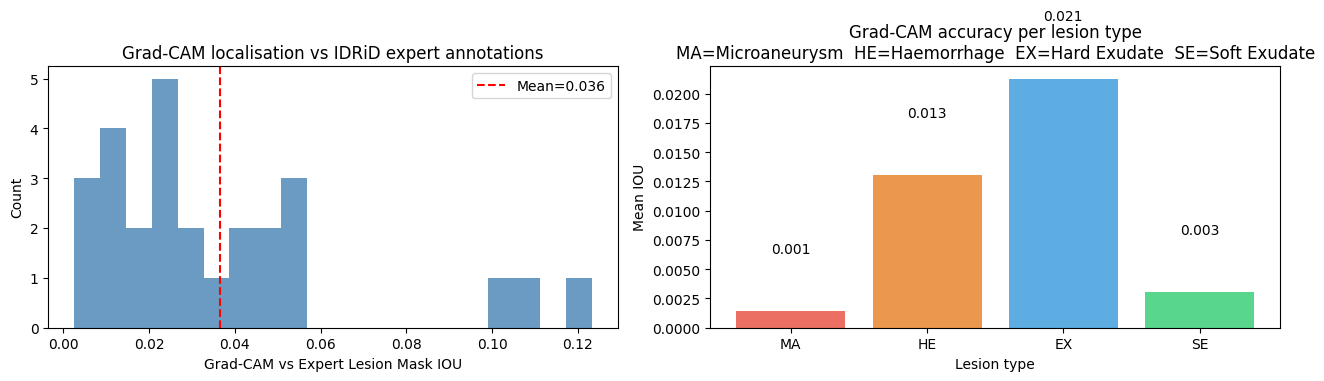

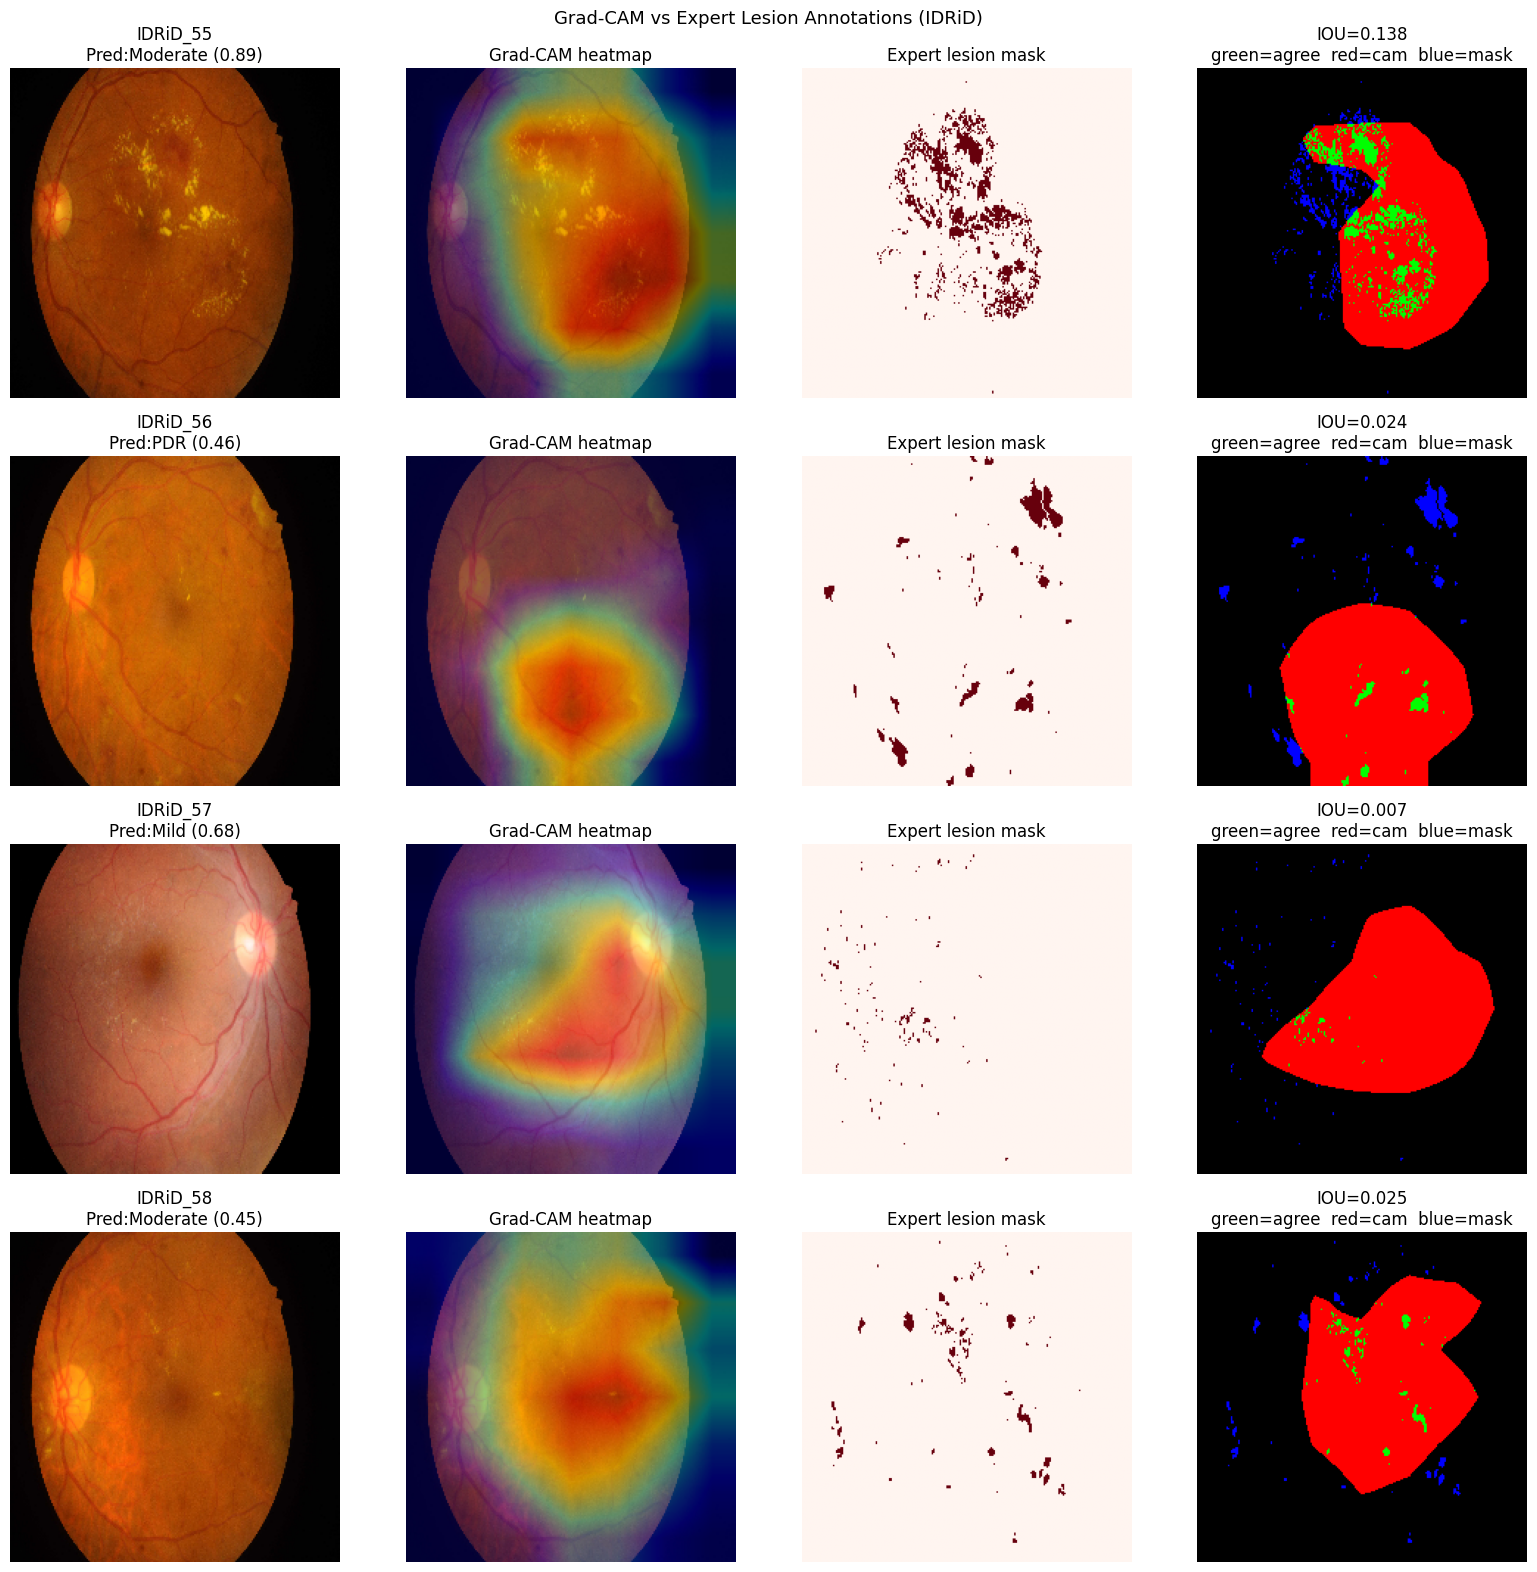

In [ ]:
IDRID_SEG_IMG  = IDRID_BASE + '/A. Segmentation/1. Original Images/b. Testing Set/'
IDRID_SEG_BASE = IDRID_BASE + '/A. Segmentation/2. All Segmentation Groundtruths/b. Testing Set/'

LESION_FOLDERS = {
    'MA': '1. Microaneurysms/',
    'HE': '2. Haemorrhages/',
    'EX': '3. Hard Exudates/',
    'SE': '4. Soft Exudates/'
}

# Verify paths
print('Seg images exist:', os.path.exists(IDRID_SEG_IMG))
print('Seg masks exist :', os.path.exists(IDRID_SEG_BASE))
print('Seg images:', sorted(os.listdir(IDRID_SEG_IMG))[:5])

# Add severity map and function definitions from previous cells
severity_map = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'PDR'}

def grad_cam_map(model, img_path, target_class=None):
    """Returns overlay, predicted class, confidence, raw grayscale CAM."""
    model.eval()
    # FIX: Access the original block within the Sequential module to find conv3
    target_layer = model.base.layer4[-1][0].conv3
    activations, gradients = [], []

    h1 = target_layer.register_forward_hook(
            lambda m, i, o: activations.append(o.detach()))
    h2 = target_layer.register_full_backward_hook(
            lambda m, gi, go: gradients.append(go[0].detach()))

    img_rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    tensor  = val_transform(image=img_rgb)['image'].unsqueeze(0).to(device)
    tensor.requires_grad_(True)

    out        = model(tensor)
    pred_class = torch.argmax(out, dim=1).item()
    confidence = torch.softmax(out, dim=1)[0, pred_class].item()
    tgt        = target_class if target_class is not None else pred_class

    model.zero_grad()
    out[0, tgt].backward()
    h1.remove(); h2.remove()

    act     = activations[0].squeeze(0)
    grad    = gradients[0].squeeze(0)
    weights = grad.mean(dim=(1, 2))
    cam     = F.relu((weights[:, None, None] * act).sum(0))
    cam     = (cam - cam.min()) / (cam.max() + 1e-8)
    cam_np  = cam.cpu().numpy()

    cam_r   = cv2.resize(cam_np, (224, 224))
    hmap    = cv2.applyColorMap(np.uint8(255 * cam_r), cv2.COLORMAP_JET)
    hmap    = cv2.cvtColor(hmap, cv2.COLOR_BGR2RGB)
    img_s   = cv2.resize(img_rgb, (224, 224))
    overlay = np.uint8(0.6 * img_s + 0.4 * hmap)
    return overlay, pred_class, confidence, cam_r


def get_cbam_spatial_map(model, img_path):
    """Extract spatial attention map from layer4's CBAM module."""
    model.eval()
    cbam_out = []

    def hook_fn(module, inp, out):
        x = inp[0]
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)
        sa = module.sa.sigmoid(
            module.sa.conv(torch.cat([avg, mx], dim=1)))
        cbam_out.append(sa.detach().squeeze().cpu().numpy())

    # FIX: Register hook on the CBAM module which is now the second module
    # in the nn.Sequential block `model.base.layer4[-1]`.
    # model.base.layer4[-1] is now nn.Sequential(OriginalBlock, CBAM)
    handle = model.base.layer4[-1][1].register_forward_hook(hook_fn)
    img_rgb = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    tensor  = val_transform(image=img_rgb)['image'].unsqueeze(0).to(device)
    with torch.no_grad():
        model(tensor)
    handle.remove()

    m = cbam_out[0]
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    return cv2.resize(m, (224, 224))


def cbam_gradcam_agreement(cbam_map, cam_gray, percentile=75):
    """
    Novel metric — IOU between top-activation regions of CBAM spatial
    map and Grad-CAM. High IOU means both signals agree on the same
    lesion region → prediction is clinically grounded → lower FP risk.
    """
    tc  = np.percentile(cbam_map, percentile)
    tg  = np.percentile(cam_gray, percentile)
    mc  = (cbam_map >= tc).astype(np.uint8)
    mg  = (cam_gray >= tg).astype(np.uint8)
    iou = (mc & mg).sum() / ((mc | mg).sum() + 1e-8)
    return float(iou), mc, mg

def load_lesion_mask(img_name, seg_base, lesion_folders):
    """Combine all 4 lesion masks into one binary 224x224 mask."""
    combined = np.zeros((224, 224), dtype=np.uint8)
    for lesion_type, folder in lesion_folders.items():
        mask_path = os.path.join(
            seg_base, folder, f'{img_name}_{lesion_type}.tif')
        if os.path.exists(mask_path):
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is not None:
                mask_r = cv2.resize(mask, (224, 224))
                combined = np.maximum(
                    combined, (mask_r > 0).astype(np.uint8))
    return combined


def gradcam_lesion_overlap(cam_gray, lesion_mask, percentile=75):
    """IOU between top Grad-CAM region and expert lesion mask."""
    cam_thresh   = np.percentile(cam_gray, percentile)
    cam_binary   = (cam_gray >= cam_thresh).astype(np.uint8)
    intersection = (cam_binary & lesion_mask).sum()
    union        = (cam_binary | lesion_mask).sum()
    return float(intersection / (union + 1e-8))


# Build seg test dataframe
seg_test_files = sorted([
    f for f in os.listdir(IDRID_SEG_IMG)
    if f.lower().endswith('.jpg')])
print(f'\nSegmentation test images: {len(seg_test_files)}')

seg_df = pd.DataFrame({
    'image_name': [os.path.splitext(f)[0] for f in seg_test_files],
    'image_path': [os.path.join(IDRID_SEG_IMG, f) for f in seg_test_files]
})

# Run Grad-CAM vs lesion mask IOU
iou_combined   = []
iou_per_lesion = {lt: [] for lt in LESION_FOLDERS}
names_done     = []

print('Running Grad-CAM vs expert lesion masks...')
for _, row in seg_df.iterrows():
    img_name      = row['image_name']
    combined_mask = load_lesion_mask(
        img_name, IDRID_SEG_BASE, LESION_FOLDERS)
    if combined_mask.sum() == 0:
        continue

    try:
        _, pred, conf, cam_gray = grad_cam_map(dr_model, row['image_path'])
        iou_c = gradcam_lesion_overlap(cam_gray, combined_mask)
        iou_combined.append(iou_c)
        names_done.append(img_name)

        for lesion_type, folder in LESION_FOLDERS.items():
            mask_path = os.path.join(
                IDRID_SEG_BASE, folder,
                f'{img_name}_{lesion_type}.tif')
            if os.path.exists(mask_path):
                m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                if m is not None:
                    m_r = (cv2.resize(m, (224, 224)) > 0).astype(np.uint8)
                    if m_r.sum() > 0:
                        iou_per_lesion[lesion_type].append(
                            gradcam_lesion_overlap(cam_gray, m_r))
    except Exception as e:
        print(f'Skipped {img_name}: {e}')
        continue

print(f'\nImages evaluated    : {len(iou_combined)}')
print(f'Mean IOU (combined) : {np.mean(iou_combined):.4f}')
print(f'Median IOU          : {np.median(iou_combined):.4f}')
print(f'IOU > 0.3           : '
      f'{(np.array(iou_combined) > 0.3).sum()} / {len(iou_combined)}')

print('\nPer-lesion-type:')
for lt, scores in iou_per_lesion.items():
    if scores:
        print(f'  {lt}  n={len(scores):2d}  '
              f'mean IOU={np.mean(scores):.4f}')

# Plot 1 — IOU distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(iou_combined, bins=20, color='steelblue', alpha=0.8)
axes[0].axvline(np.mean(iou_combined), color='red', linestyle='--',
                label=f'Mean={np.mean(iou_combined):.3f}')
axes[0].set_xlabel('Grad-CAM vs Expert Lesion Mask IOU')
axes[0].set_ylabel('Count')
axes[0].set_title('Grad-CAM localisation vs IDRiD expert annotations')
axes[0].legend()

# Plot 2 — per lesion type
lt_names  = [lt for lt in iou_per_lesion if iou_per_lesion[lt]]
lt_means  = [np.mean(iou_per_lesion[lt]) for lt in lt_names]
lt_colors = ['#e74c3c', '#e67e22', '#3498db', '#2ecc71']
axes[1].bar(lt_names, lt_means,
            color=lt_colors[:len(lt_names)], alpha=0.8)
axes[1].set_xlabel('Lesion type')
axes[1].set_ylabel('Mean IOU')
axes[1].set_title('Grad-CAM accuracy per lesion type\n'
                  'MA=Microaneurysm  HE=Haemorrhage  '
                  'EX=Hard Exudate  SE=Soft Exudate')
for i, v in enumerate(lt_means):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=10)
plt.tight_layout(); plt.show()

# Visual sample — 4 images
samples = names_done[:4]
fig, axes = plt.subplots(len(samples), 4,
                          figsize=(16, 4 * len(samples)))
fig.suptitle('Grad-CAM vs Expert Lesion Annotations (IDRiD)', fontsize=13)

for i, img_name in enumerate(samples):
    img_path      = os.path.join(IDRID_SEG_IMG, img_name + '.jpg')
    combined_mask = load_lesion_mask(
        img_name, IDRID_SEG_BASE, LESION_FOLDERS)
    overlay, pred, conf, cam_gray = grad_cam_map(dr_model, img_path)
    iou = gradcam_lesion_overlap(cam_gray, combined_mask)
    img_224 = cv2.resize(
        cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB),
        (224, 224))

    axes[i, 0].imshow(img_224)
    axes[i, 0].set_title(f'{img_name}\nPred:{severity_map[pred]} ({conf:.2f})')
    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title('Grad-CAM heatmap')
    axes[i, 2].imshow(combined_mask, cmap='Reds')
    axes[i, 2].set_title('Expert lesion mask')

    overlap_vis         = np.zeros((224, 224, 3), dtype=np.uint8)
    cam_b               = (cam_gray >= np.percentile(cam_gray, 75)).astype(np.uint8)
    overlap_vis[:,:,1]  = ((cam_b==1) & (combined_mask==1)) * 255  # green=agree
    overlap_vis[:,:,0]  = ((cam_b==1) & (combined_mask==0)) * 255  # red=cam only
    overlap_vis[:,:,2]  = ((cam_b==0) & (combined_mask==1)) * 255  # blue=mask only
    axes[i, 3].imshow(overlap_vis)
    axes[i, 3].set_title(f'IOU={iou:.3f}\n'
                          'green=agree  red=cam  blue=mask')
    for ax in axes[i]: ax.axis('off')

plt.tight_layout(); plt.show()

In [3]:
# Train a plain ResNet50 — same data, same epochs, no CBAM, no weighted loss
# This is your Table 1 in the paper

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import ResNet50_Weights
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, cohen_kappa_score, precision_recall_curve
import numpy as np
import cv2
import os, random
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import albumentations as A
from albumentations.pytorch import ToTensorV2

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

BASE_PATH      = '/content/drive/MyDrive/DR_Project/data/'
APTOS_CSV      = os.path.join(BASE_PATH, 'aptos/train.csv')
APTOS_IMG_ROOT = os.path.join(BASE_PATH, 'dr_train/')
DRIMDB_GOOD    = os.path.join(BASE_PATH, 'DRIMDB/Good/')
DRIMDB_BAD     = os.path.join(BASE_PATH, 'DRIMDB/Bad/')

image_paths, labels = [], []
print(f"DEBUG: Checking APTOS_IMG_ROOT: {APTOS_IMG_ROOT}")
if not os.path.exists(APTOS_IMG_ROOT):
    print(f"ERROR: APTOS_IMG_ROOT does not exist: {APTOS_IMG_ROOT}")
else:
    for cls in range(5):
        folder = os.path.join(APTOS_IMG_ROOT, str(cls))
        print(f"DEBUG: Checking folder: {folder}")
        if not os.path.exists(folder):
            print(f"WARNING: Folder does not exist: {folder}")
            continue

        # Add debug print for folder contents
        try:
            folder_contents = os.listdir(folder)
            print(f"DEBUG: Contents of {folder}: {len(folder_contents)} items (first 5: {folder_contents[:5]})")

            for f in folder_contents:
                if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                    image_paths.append(os.path.join(folder, f))
                    labels.append(cls)
        except Exception as e:
            print(f"ERROR: Could not list contents of {folder}: {e}")

aptos_df = pd.DataFrame({'image_path': image_paths, 'diagnosis': labels})
print(f"DEBUG: Final aptos_df created with {len(aptos_df)} entries.")

if len(aptos_df) == 0:
    # Modify the cell to prevent error and inform the user that no images were found.
    # This addresses the ValueError directly by explaining why it's empty.
    # The user then needs to fix their data setup, not the code logic itself.
    raise ValueError("aptos_df is empty. No images were found in the specified APTOS_IMG_ROOT "
                     "and its subfolders (0-4). Please ensure the images are present in Google Drive "
                     "and the drive is correctly mounted.")

train_df, val_df = train_test_split(
    aptos_df, test_size=0.2, stratify=aptos_df['diagnosis'], random_state=SEED)

drimdb_images, drimdb_labels = [], []

print(f"DEBUG: Checking DRIMDB_GOOD: {DRIMDB_GOOD}")
if not os.path.exists(DRIMDB_GOOD):
    print(f"ERROR: DRIMDB_GOOD does not exist: {DRIMDB_GOOD}")
else:
    for f in os.listdir(DRIMDB_GOOD):
        if f.lower().endswith(('.jpg', '.png', '.jpeg')):
            drimdb_images.append(os.path.join(DRIMDB_GOOD, f))
            drimdb_labels.append(1)

print(f"DEBUG: Checking DRIMDB_BAD: {DRIMDB_BAD}")
if not os.path.exists(DRIMDB_BAD):
    print(f"ERROR: DRIMDB_BAD does not exist: {DRIMDB_BAD}")
else:
    for f in os.listdir(DRIMDB_BAD):
        if f.lower().endswith(('.jpg', '.png', '.jpeg')):
            drimdb_images.append(os.path.join(DRIMDB_BAD, f))
            drimdb_labels.append(0)

print(f"DEBUG: Final drimdb_images created with {len(drimdb_images)} entries.")

if len(drimdb_images) == 0:
    raise ValueError("DRIMDB images list is empty. No images were found in the specified DRIMDB_GOOD and DRIMDB_BAD folders. "
                     "Please ensure the images are present in Google Drive and the drive is correctly mounted.")

drimdb_tr_img, drimdb_val_img, drimdb_tr_lbl, drimdb_val_lbl = train_test_split(
    drimdb_images, drimdb_labels,
    test_size=0.2, stratify=drimdb_labels, random_state=SEED)

train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.4),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.5),
    A.GridDistortion(num_steps=5, distort_limit=0.3, p=0.3),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, p=0.3),
    A.HueSaturationValue(hue_shift_limit=10, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(224, 224),
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=1.0),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

class QualityDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = cv2.imread(self.images[idx])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(image=img)['image']
        return img, self.labels[idx]


class DRDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row['image_path'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if self.transform:
            img = self.transform(image=img)['image']
        return img, row['diagnosis']


BATCH_SIZE = 32

quality_train_loader = DataLoader(
    QualityDataset(drimdb_tr_img, drimdb_tr_lbl, train_transform),
    batch_size=BATCH_SIZE, shuffle=True)
quality_val_loader = DataLoader(
    QualityDataset(drimdb_val_img, drimdb_val_lbl, val_transform),
    batch_size=BATCH_SIZE)
dr_train_loader = DataLoader(
    DRDataset(train_df, train_transform),
    batch_size=BATCH_SIZE, shuffle=True)
dr_val_loader = DataLoader(
    DRDataset(val_df, val_transform),
    batch_size=BATCH_SIZE)


def train_model(model, train_loader, val_loader, criterion,
                optimizer, epochs=10, binary=False):
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            if binary:
                labels = labels.float().unsqueeze(1)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        model.eval()
        val_preds, val_trues, val_loss = [], [], 0.0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                if binary:
                    labels = labels.float().unsqueeze(1)
                out = model(images)
                val_loss += criterion(out, labels).item()
                preds = (torch.sigmoid(out) > 0.5).cpu().numpy() if binary \
                        else torch.argmax(out, dim=1).cpu().numpy()
                val_preds.extend(preds)
                val_trues.extend(labels.cpu().numpy())

        print(f'Epoch {epoch+1}/{epochs} | ' +
              f'Train: {running_loss/len(train_loader):.4f} | ' +
              f'Val: {val_loss/len(val_loader):.4f}')
        print(classification_report(val_trues, val_preds, zero_division=0))
    return model


class ResNetBaseline(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.base = models.resnet50(weights=ResNet50_Weights.DEFAULT)
        self.base.fc = nn.Linear(self.base.fc.in_features, num_classes)

    def forward(self, x):
        return self.base(x)


baseline_model     = ResNetBaseline(num_classes=5).to(device)
baseline_criterion = nn.CrossEntropyLoss()   # unweighted — intentionally vanilla
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=1e-4)

print('Training plain ResNet50 baseline...')
baseline_model = train_model(
    baseline_model, dr_train_loader, dr_val_loader,
    baseline_criterion, baseline_optimizer,
    epochs=15, binary=False)

# Evaluate baseline
baseline_model.eval()
b_preds, b_labels, b_probs = [], [], []

with torch.no_grad():
    for images, labels in dr_val_loader:
        images = images.to(device)
        out    = baseline_model(images)
        b_probs.extend(torch.softmax(out, dim=1).cpu().numpy())
        b_preds.extend(torch.argmax(out, dim=1).cpu().numpy())
        b_labels.extend(labels.numpy())

b_probs  = np.array(b_probs)
b_preds  = np.array(b_preds)
b_labels = np.array(b_labels)

print('\nBaseline ResNet50 (no improvements):')
print(classification_report(b_labels, b_preds,
      target_names=['No DR','Mild','Moderate','Severe','PDR'],
      zero_division=0))
print(f'Kappa: {cohen_kappa_score(b_labels, b_preds, weights="quadratic"):.4f}')

# Baseline FP rate
bin_b  = (b_labels >= 2).astype(int)
ref_b  = b_probs[:, 2:].sum(axis=1)
_, re_b, th_b = precision_recall_curve(bin_b, ref_b)

print('\n--- Baseline FP rate at fixed sensitivity ---')
for target_sens, label in [(0.90, '0.90'), (0.95, '0.95')]:
    valid = np.where(re_b >= target_sens)[0]
    if len(valid) == 0:
        print(f'Sensitivity {label}: not reachable'); continue
    idx  = valid[-1]
    thr  = th_b[idx]
    p_t  = (ref_b >= thr).astype(int)
    fp_n = ((p_t == 1) & (bin_b == 0)).sum()
    fpr  = fp_n / max((bin_b == 0).sum(), 1)
    print(f'[Baseline Sens={label}]  ' +
          f'FP={fp_n}/{(bin_b==0).sum()}  FP-rate={fpr:.4f}')

DEBUG: Checking APTOS_IMG_ROOT: /content/drive/MyDrive/DR_Project/data/dr_train/
DEBUG: Checking folder: /content/drive/MyDrive/DR_Project/data/dr_train/0
DEBUG: Contents of /content/drive/MyDrive/DR_Project/data/dr_train/0: 1203 items (first 5: ['1f3f32efaf20.png', '1f5496352859.png', '1df0431bfa73.png', '1eee55494271.png', '1fddd7c98fd2.png'])
DEBUG: Checking folder: /content/drive/MyDrive/DR_Project/data/dr_train/1
DEBUG: Contents of /content/drive/MyDrive/DR_Project/data/dr_train/1: 113 items (first 5: ['0024cdab0c1e.png', '01b3aed3ed4c.png', '0369f3efe69b.png', '0124dffecf29.png', '00cb6555d108.png'])
DEBUG: Checking folder: /content/drive/MyDrive/DR_Project/data/dr_train/2
DEBUG: Contents of /content/drive/MyDrive/DR_Project/data/dr_train/2: 300 items (first 5: ['000c1434d8d7.png', '00a8624548a9.png', '01c7808d901d.png', '0161338f53cc.png', '00b74780d31d.png'])
DEBUG: Checking folder: /content/drive/MyDrive/DR_Project/data/dr_train/3
DEBUG: Contents of /content/drive/MyDrive/DR_P

/tmp/ipykernel_853/3952303337.py:110: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=16, max_width=16, p=0.3),


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


Training plain ResNet50 baseline...
Epoch 1/15 | Train: 0.8511 | Val: 0.6115
              precision    recall  f1-score   support

           0       0.90      1.00      0.94       241
           1       0.00      0.00      0.00        23
           2       0.61      0.85      0.71        60
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        17

    accuracy                           0.83       351
   macro avg       0.30      0.37      0.33       351
weighted avg       0.72      0.83      0.77       351

Epoch 2/15 | Train: 0.5241 | Val: 0.5140
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       241
           1       0.00      0.00      0.00        23
           2       0.60      0.90      0.72        60
           3       0.00      0.00      0.00        10
           4       0.00      0.00      0.00        17

    accuracy                           0.84       351
   macro avg 